# GRB 081203A Afterglow Lightcurve MCMC Fit
This notebook performs MCMC fitting for various power-law models to estimate precise errors via Bayesian inference.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import emcee
import corner
from scipy.optimize import curve_fit
import warnings

warnings.filterwarnings("ignore")

# Read data
data = pd.read_csv('GRB081203A.ascii', sep=r'\s+')
t = data['time'].values
mag = data['mag'].values
mag_err = data['mag_err'].values

F = 3631 * 10**6 * 10**(-0.4 * mag)
F_err = F * (np.log(10) / 2.5) * mag_err

Save time, Flyx, Flux_err to CSV

In [ ]:
# Save results to CSV
output_df = pd.DataFrame({
    'time_s': t,
    'flux_uJy': F,
    'flux_err_uJy': F_err
})
output_df.to_csv('flux_data.csv', index=False)
print("\nFlux data (time, flux, flux_err) saved to flux_data.csv")

## Model Definitions

In [ ]:
def single_pl(t, K, alpha):
    return K * (t / 1000.0)**(-alpha)

def broken_pl(t, K, alpha1, alpha2, tb, s):
    return K * ((t / tb)**(alpha1 * s) + (t / tb)**(alpha2 * s))**(-1.0 / s)

def piecewise_bpl(t, K, alpha1, alpha2, tb):
    return np.piecewise(t, [t < tb, t >= tb],
                        [lambda t: K * (t / tb)**(-alpha1),
                         lambda t: K * (t / tb)**(-alpha2)])

def double_piecewise_bpl(t, K, alpha1, alpha2, alpha3, tb1, tb2):
    return np.piecewise(t, [t < tb1, (t >= tb1) & (t < tb2), t >= tb2],
                        [lambda t: K * (t / tb1)**(-alpha1),
                         lambda t: K * (t / tb1)**(-alpha2),
                         lambda t: K * (tb2 / tb1)**(-alpha2) * (t / tb2)**(-alpha3)])

def double_smooth_bpl(t, K, alpha1, alpha2, alpha3, tb1, tb2, s1, s2):
    term1 = ((t / tb1)**(alpha1 * s1) + (t / tb1)**(alpha2 * s1))**(-1.0 / s1)
    term2 = (1.0 + (t / tb2)**s2)**((alpha2 - alpha3) / s2)
    return K * term1 * term2

## Helper Function for MCMC

In [ ]:
def run_mcmc(model_func, p0, bounds, labels, nsteps=3000, nwalkers=32):
    print(f"\n--- Running MCMC for {model_func.__name__} ---")
    np.random.seed(42)
    popt, _ = curve_fit(model_func, t, F, sigma=F_err, p0=p0, bounds=bounds, maxfev=100000)
    
    def log_prior(theta):
        for i, (lower, upper) in enumerate(zip(bounds[0], bounds[1])):
            if not (lower < theta[i] < upper):
                return -np.inf
        return 0.0

    def log_likelihood(theta):
        model_flux = model_func(t, *theta)
        sigma2 = F_err**2
        return -0.5 * np.sum((F - model_flux)**2 / sigma2 + np.log(2 * np.pi * sigma2))

    def log_probability(theta):
        lp = log_prior(theta)
        if not np.isfinite(lp):
            return -np.inf
        return lp + log_likelihood(theta)

    ndim = len(popt)
    pos = popt + 1e-4 * np.random.randn(nwalkers, ndim)
    
    sampler = emcee.EnsembleSampler(nwalkers, ndim, log_probability)
    sampler.run_mcmc(pos, nsteps, progress=True)
    
    flat_samples = sampler.get_chain(discard=nsteps//3, thin=15, flat=True)
    
    print("\nResults (50th percentile, with 16th and 84th percentile errors):")
    results = {}
    for i in range(ndim):
        mcmc = np.percentile(flat_samples[:, i], [16, 50, 84])
        q = np.diff(mcmc)
        print(f"{labels[i]} = {mcmc[1]:.4f} +{q[1]:.4f} / -{q[0]:.4f}")
        results[labels[i]] = (mcmc[1], q[1], q[0])
        
    fig = corner.corner(flat_samples, labels=labels, truths=popt, quantiles=[0.16, 0.5, 0.84], show_titles=True, title_kwargs={"fontsize": 12})
    fig.savefig(f"corner_{model_func.__name__}.png")
    plt.close(fig)
    
    return results

## Run MCMC for all models

In [ ]:
all_results = {}

# 1. Single PL
p0_spl = [np.max(F), 1.0]
bounds_spl = ([0, -5], [np.inf, 5])
labels_spl = ["K", "alpha"]
all_results['Single PL'] = run_mcmc(single_pl, p0_spl, bounds_spl, labels_spl)

# 2. Broken PL (Piecewise)
p0_pw = [np.max(F), -1.0, 1.5, 300.0]
bounds_pw = ([0, -5, -5, 10], [np.inf, 5, 5, 1e6])
labels_pw = ["K", "alpha1", "alpha2", "tb"]
all_results['Broken PL (Piecewise)'] = run_mcmc(piecewise_bpl, p0_pw, bounds_pw, labels_pw)

# 3. Broken PL (Smooth)
p0_bpl = [np.max(F), -1.0, 1.5, 300.0, 1.0]
bounds_bpl = ([0, -5, -5, 10, 0.1], [np.inf, 5, 5, 1e6, 10])
labels_bpl = ["K", "alpha1", "alpha2", "tb", "s"]
all_results['Broken PL (Smooth)'] = run_mcmc(broken_pl, p0_bpl, bounds_bpl, labels_bpl)

# 4. Double Broken PL (Piecewise)
p0_dpw = [np.max(F), -1.0, 1.5, 2.0, 300.0, 20000.0]
bounds_dpw = ([0, -5, -5, -5, 10, 1000], [np.inf, 5, 5, 5, 1e5, 1e6])
labels_dpw = ["K", "alpha1", "alpha2", "alpha3", "tb1", "tb2"]
all_results['Double Broken PL (Piecewise)'] = run_mcmc(double_piecewise_bpl, p0_dpw, bounds_dpw, labels_dpw)

# 5. Double Broken PL (Smooth)
p0_ds = [np.max(F), -1.0, 1.5, 2.0, 300.0, 20000.0, 1.0, 1.0]
bounds_ds = ([0, -5, -5, -5, 10, 1000, 0.1, 0.1], [np.inf, 5, 5, 5, 1e5, 1e6, 10.0, 10.0])
labels_ds = ["K", "alpha1", "alpha2", "alpha3", "tb1", "tb2", "s1", "s2"]
all_results['Double Broken PL (Smooth)'] = run_mcmc(double_smooth_bpl, p0_ds, bounds_ds, labels_ds)


--- Running MCMC for single_pl ---


100%|██████████| 3000/3000 [00:00<00:00, 3008.41it/s]



Results (50th percentile, with 16th and 84th percentile errors):
K = 1052.5546 +12.5190 / -13.2625
alpha = 0.8021 +0.0035 / -0.0035

--- Running MCMC for piecewise_bpl ---


100%|██████████| 3000/3000 [00:01<00:00, 1806.85it/s]



Results (50th percentile, with 16th and 84th percentile errors):
K = 26202.6232 +278.2170 / -298.3588
alpha1 = -1.1797 +0.0194 / -0.0193
alpha2 = 1.4215 +0.0074 / -0.0070
tb = 416.6551 +3.5289 / -3.4033

--- Running MCMC for broken_pl ---


...


Results (50th percentile, with 16th and 84th percentile errors):
K = 52091.1380 +4884.1223 / -4246.9839
alpha1 = -2.1580 +0.1438 / -0.1440
alpha2 = 1.5043 +0.0148 / -0.0152
tb = 308.8397 +13.4856 / -12.4649
s = 0.8056 +0.0987 / -0.0879

--- Running MCMC for double_piecewise_bpl ---


100%|██████████| 3000/3000 [00:01<00:00, 1503.02it/s]



Results (50th percentile, with 16th and 84th percentile errors):
K = 27414.9922 +418.6107 / -1246.5714
alpha1 = -1.3435 +0.1543 / -0.0287
alpha2 = 1.3689 +0.0311 / -0.0081
alpha3 = 2.2625 +0.8716 / -0.3644
tb1 = 369.5367 +41.9612 / -3.9404
tb2 = 27078.7033 +10038.5437 / -7228.3830

--- Running MCMC for double_smooth_bpl ---


100%|██████████| 3000/3000 [00:01<00:00, 2365.69it/s]



Results (50th percentile, with 16th and 84th percentile errors):
K = 49244.2340 +4730.2663 / -3586.9287
alpha1 = -2.0938 +0.1258 / -0.1511
alpha2 = 1.4892 +0.0177 / -0.0155
alpha3 = 2.5504 +1.4414 / -0.7861
tb1 = 312.2681 +12.2268 / -12.3518
tb2 = 145498.6632 +458881.3154 / -105427.8334
s1 = 0.8686 +0.0999 / -0.1027
s2 = 4.4473 +4.0375 / -2.7208


In [ ]:
# Calculate BIC, Chi2/dof and save all MCMC results to CSV
formatted_results = []
n_points = len(t)
log_L_const = np.sum(np.log(2 * np.pi * F_err**2))

for model_name, params in all_results.items():
    row = {'Model': model_name}
    for param_name, (median, up, down) in params.items():
        row[f'{param_name}'] = median
        row[f'{param_name}_err_up'] = up
        row[f'{param_name}_err_down'] = down
        
    if model_name == 'Single PL':
        k = 2
        model_F = single_pl(t, params['K'][0], params['alpha'][0])
    elif model_name == 'Broken PL (Piecewise)':
        k = 4
        model_F = piecewise_bpl(t, params['K'][0], params['alpha1'][0], params['alpha2'][0], params['tb'][0])
    elif model_name == 'Broken PL (Smooth)':
        k = 5
        model_F = broken_pl(t, params['K'][0], params['alpha1'][0], params['alpha2'][0], params['tb'][0], params['s'][0])
    elif model_name == 'Double Broken PL (Piecewise)':
        k = 6
        model_F = double_piecewise_bpl(t, params['K'][0], params['alpha1'][0], params['alpha2'][0], params['alpha3'][0], params['tb1'][0], params['tb2'][0])
    elif model_name == 'Double Broken PL (Smooth)':
        k = 8
        model_F = double_smooth_bpl(t, params['K'][0], params['alpha1'][0], params['alpha2'][0], params['alpha3'][0], params['tb1'][0], params['tb2'][0], params['s1'][0], params['s2'][0])
    
    chi2 = np.sum(((F - model_F) / F_err)**2)
    dof = n_points - k
    bic = chi2 + log_L_const + k * np.log(n_points)
    
    row['Chi2_dof'] = chi2 / dof
    row['BIC'] = bic
    
    formatted_results.append(row)
    
df_mcmc = pd.DataFrame(formatted_results)
df_mcmc.to_csv("all_models_mcmc_results.csv", index=False)
print("\nAll MCMC results with stats saved to all_models_mcmc_results.csv")


All MCMC results with stats saved to all_models_mcmc_results.csv


## Plot MCMC Lightcurve

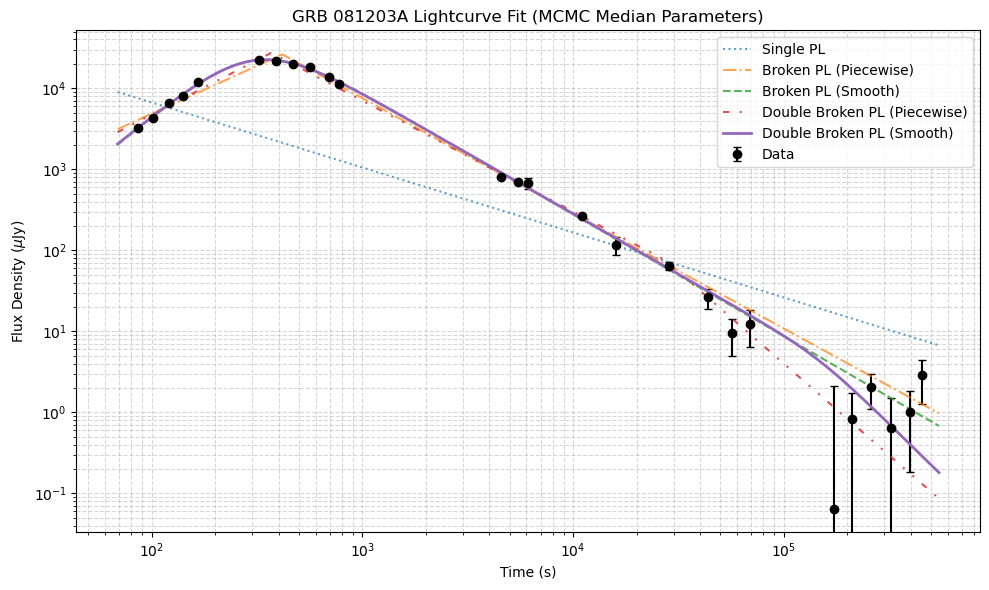

Plot saved to lightcurve_fit_mcmc.png


In [ ]:
mcmc_df_plot = pd.read_csv('all_models_mcmc_results.csv')
mcmc_df_plot.set_index('Model', inplace=True)

t_plot = np.logspace(np.log10(min(t)*0.8), np.log10(max(t)*1.2), 500)
plt.figure(figsize=(10, 6))
plt.errorbar(t, F, yerr=F_err, fmt='o', label='Data', color='black', capsize=3)

# Plot each model using its MCMC median parameters
try:
    row = mcmc_df_plot.loc['Single PL']
    plt.plot(t_plot, single_pl(t_plot, row['K'], row['alpha']), label='Single PL', linestyle=':', alpha=0.7)
except Exception as e: print("Skipped Single PL", e)

try:
    row = mcmc_df_plot.loc['Broken PL (Piecewise)']
    plt.plot(t_plot, piecewise_bpl(t_plot, row['K'], row['alpha1'], row['alpha2'], row['tb']), label='Broken PL (Piecewise)', linestyle='-.', alpha=0.7)
except Exception as e: print("Skipped Piecewise BPL", e)

try:
    row = mcmc_df_plot.loc['Broken PL (Smooth)']
    plt.plot(t_plot, broken_pl(t_plot, row['K'], row['alpha1'], row['alpha2'], row['tb'], row['s']), label='Broken PL (Smooth)', linestyle='--', alpha=0.8)
except Exception as e: print("Skipped Smooth BPL", e)

try:
    row = mcmc_df_plot.loc['Double Broken PL (Piecewise)']
    plt.plot(t_plot, double_piecewise_bpl(t_plot, row['K'], row['alpha1'], row['alpha2'], row['alpha3'], row['tb1'], row['tb2']), label='Double Broken PL (Piecewise)', linestyle=(0, (3, 5, 1, 5, 1, 5)), alpha=0.8)
except Exception as e: print("Skipped Double Piecewise BPL", e)

try:
    row = mcmc_df_plot.loc['Double Broken PL (Smooth)']
    plt.plot(t_plot, double_smooth_bpl(t_plot, row['K'], row['alpha1'], row['alpha2'], row['alpha3'], row['tb1'], row['tb2'], row['s1'], row['s2']), label='Double Broken PL (Smooth)', linestyle='-', linewidth=2)
except Exception as e: print("Skipped Double Smooth BPL", e)

plt.xscale('log')
plt.yscale('log')
plt.xlabel('Time (s)')
plt.ylabel(r'Flux Density ($\mu$Jy)')
plt.title('GRB 081203A Lightcurve Fit (MCMC Median Parameters)')
plt.legend()
plt.grid(True, which='both', ls='--', alpha=0.5)
plt.tight_layout()
plt.savefig('lightcurve_fit_mcmc.png')
plt.show()
print("Plot saved to lightcurve_fit_mcmc.png")

## Generate LaTeX Table

In [ ]:
df_tex = pd.read_csv('all_models_mcmc_results.csv')

params = ['K', 'alpha1', 'alpha2', 'alpha3', 'tb1', 'tb2', 's1', 's2']
latex_labels = {
    'K': r'$K$ ($\mu$Jy)',
    'alpha1': r'$\alpha_1$',
    'alpha2': r'$\alpha_2$',
    'alpha3': r'$\alpha_3$',
    'tb1': r'$t_{b,1}$ (s)',
    'tb2': r'$t_{b,2}$ (s)',
    's1': r'$s_1$',
    's2': r'$s_2$'
}

tex = []
tex.append(r'\begin{table*}[htbp]')
tex.append(r'\centering')
tex.append(r'\caption{MCMC Median Parameters, $\chi^2$/dof, and BIC for GRB 081203A Afterglow}')
tex.append(r'\label{tab:mcmc_results_stats}')
tex.append(r'\resizebox{\textwidth}{!}{%')
tex.append(r'\begin{tabular}{l' + 'c'*(len(params)+2) + r'}')
tex.append(r'\hline\hline')
headers = ['Model'] + [latex_labels[p] for p in params] + [r'$\chi^2$/dof', 'BIC']
tex.append(' & '.join(headers) + r' \\')
tex.append(r'\hline')

for idx, row in df_tex.iterrows():
    line = [row['Model']]
    for p in params:
        val = row.get(p)
        if pd.isna(val):
            line.append('--')
        else:
            up = row.get(f'{p}_err_up')
            down = row.get(f'{p}_err_down')
            
            # Format values
            if p == 'K' or p.startswith('tb'):
                if val > 1000:
                    line.append(f"${val:.0f}^{{+{up:.0f}}}_{{-{down:.0f}}}$")
                else:
                    line.append(f"${val:.1f}^{{+{up:.1f}}}_{{-{down:.1f}}}$")
            else:
                line.append(f"${val:.2f}^{{+{up:.2f}}}_{{-{down:.2f}}}$")
    
    # Add stats
    line.append(f"${row['Chi2_dof']:.2f}$")
    line.append(f"${row['BIC']:.2f}$")
    
    tex.append(' & '.join(line) + r' \\')

tex.append(r'\hline')
tex.append(r'\end{tabular}%')
tex.append(r'}')
tex.append(r'\end{table*}')

with open('mcmc_table.tex', 'w') as f:
    f.write('\n'.join(tex))
    
print("LaTeX table generated and saved to mcmc_table.tex")

LaTeX table generated and saved to mcmc_table.tex
